# ecDNA and whole-genome completion-time bounds

This notebook separates the analysis into two workflows.

1. **Localised ecDNA regions.** These are treated as circular domains and compared only with the torus bound $T_L$.
2. **Whole-genome or whole-chromosome timing profiles.** These are treated as non-periodic profiles and compared with the full-line bound $\mathbb{R}$.

Shared definitions for Repli-seq extraction, curve polishing, DNAscape fitting and simulation, and Proposition 1 bounds are collected first. The two analysis sections can then be run independently, one dataset at a time.

## 1. Shared imports and global settings

Change `DATA_DIR` if your bigWig files are not stored under `data/repliseq/`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pybigtools
from IPython.display import display

# DNAscape core functions: rfit, rsim, plotf, rescale, etc.
from dnascape import *

plt.rcParams.update({
    "figure.figsize": (7.2, 4.6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
})

warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA_DIR = Path("data/repliseq")
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

S_PHASE_BINS = ["S1", "S2", "S3", "S4", "S5"]
STANDARD_CHROMS = [f"chr{i}" for i in range(1, 23)] + ["chrX"]

## 2. Dataset and file helpers

The localised ecDNA analysis uses explicit genomic intervals. The whole-genome analysis can build one configuration per chromosome from the chromosome sizes stored in the bigWig files.

In [2]:
def safe_filename(text):
    return (
        str(text)
        .replace(" ", "_")
        .replace("/", "_")
        .replace(",", "")
        .replace(":", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("$", "")
        .replace("\\", "")
        .replace("+", "plus")
    )


def expected_bigwig_files(cfg, data_dir=DATA_DIR):
    return [
        data_dir / f"{cfg['cell_line']}_{sbin}_{cfg['resolution']}.bw"
        for sbin in S_PHASE_BINS
    ]


def check_required_files(configs, selected_keys=None, data_dir=DATA_DIR):
    if selected_keys is None:
        selected_keys = list(configs)

    rows = []

    for key in selected_keys:
        cfg = configs[key]

        for path in expected_bigwig_files(cfg, data_dir=data_dir):
            rows.append({
                "dataset_key": key,
                "dataset_label": cfg["label"],
                "file": str(path),
                "exists": path.exists(),
            })

    table = pd.DataFrame(rows)
    display(table)

    missing = table.loc[~table["exists"], "file"].tolist()

    if missing:
        raise FileNotFoundError(
            "Missing required bigWig files:\n" + "\n".join(missing)
        )

    return table


def get_bigwig_chrom_sizes(cell_line, resolution=10_000, data_dir=DATA_DIR, sbin="S1"):
    path = data_dir / f"{cell_line}_{sbin}_{resolution}.bw"

    if not path.exists():
        raise FileNotFoundError(f"Cannot find {path}")

    bw = pybigtools.open(str(path))

    try:
        chroms = dict(bw.chroms())
    finally:
        bw.close()

    return chroms


def build_chromosome_configs(cell_line="DM", chroms=("chr20",), resolution=10_000,
                             data_dir=DATA_DIR, analysis_tag="whole"):
    chrom_sizes = get_bigwig_chrom_sizes(
        cell_line=cell_line,
        resolution=resolution,
        data_dir=data_dir,
    )

    configs = {}

    for chrom in chroms:
        if chrom not in chrom_sizes:
            raise ValueError(f"{chrom} is not present in {cell_line}_S1_{resolution}.bw")

        chrom_length = int(chrom_sizes[chrom])
        end = chrom_length - (chrom_length % resolution)

        key = f"{cell_line}_{analysis_tag}_{chrom}"

        configs[key] = {
            "key": key,
            "label": f"{cell_line}, whole {chrom}",
            "short_label": f"{cell_line} {chrom}",
            "cell_line": cell_line,
            "chrom": chrom,
            "start": 0,
            "end": end,
            "resolution": resolution,
            "fit_periodic": False,
            "sim_periodic": False,
            "bound_geometries": ["line"],
            "analysis_type": "whole_genome",
        }

    return configs

## 3. Repli-seq timing extraction

For each genomic bin, the five S-phase bigWig signals are normalised into a probability distribution over S phase. A sigmoid is fitted to the cumulative distribution, and the midpoint is used as a raw timing value.

In [3]:
def sigmoid(x, k, x0):
    return 1.0 / (1.0 + np.exp(-k * (x - x0)))


def read_bigwig_bin_mean(bw, chrom, start, end):
    vals = bw.values(chrom, int(start), int(end))

    if vals is None:
        return np.nan

    vals = np.asarray(
        [np.nan if v is None else float(v) for v in vals],
        dtype=float,
    )

    if vals.size == 0:
        return np.nan

    return np.nanmean(vals)


def compute_timing_curve(chrom, start, end, cell_line="DM", resolution=10_000,
                         data_dir=DATA_DIR, s_phase_bins=S_PHASE_BINS):
    x_bins = np.arange(1, len(s_phase_bins) + 1, dtype=float)

    bw_files = [
        pybigtools.open(str(data_dir / f"{cell_line}_{sbin}_{resolution}.bw"))
        for sbin in s_phase_bins
    ]

    positions = np.arange(start, end, resolution, dtype=int)
    rt_values = []

    try:
        for pos in positions:
            signals = np.array([
                read_bigwig_bin_mean(bw, chrom, pos, pos + resolution)
                for bw in bw_files
            ], dtype=float)

            if np.any(~np.isfinite(signals)) or np.nansum(signals) <= 0:
                rt_values.append(np.nan)
                continue

            norm_signals = signals / np.sum(signals)
            cumulative = np.cumsum(norm_signals)

            try:
                popt, _ = curve_fit(
                    sigmoid,
                    x_bins,
                    cumulative,
                    p0=(2.0, 3.0),
                    bounds=([0.1, 1.0], [10.0, len(s_phase_bins)]),
                    maxfev=10_000,
                )
                _, x0 = popt
                rt_values.append(x0)
            except RuntimeError:
                rt_values.append(np.nan)

    finally:
        for bw in bw_files:
            bw.close()

    return positions, np.asarray(rt_values, dtype=float)


def compute_timing_curve_from_config(cfg, data_dir=DATA_DIR):
    return compute_timing_curve(
        chrom=cfg["chrom"],
        start=cfg["start"],
        end=cfg["end"],
        cell_line=cfg["cell_line"],
        resolution=cfg["resolution"],
        data_dir=data_dir,
    )

## 4. Timing-curve polishing

For localised ecDNA intervals, the default refinement converts 10 kb bins into a 1 kb grid. For whole-chromosome simulations, use a smaller refinement factor, usually `1`, otherwise the simulation can become very large.

In [4]:
def refinef_local(x, resolution_factor=1, mode="smooth"):
    x = np.asarray(x, dtype=float)

    if len(x) == 0:
        return x

    if resolution_factor <= 0:
        raise ValueError("resolution_factor must be positive")

    m = max(1, int(round(len(x) * resolution_factor)))
    u = np.clip(np.arange(m) / resolution_factor, 0, len(x) - 1)

    if mode == "smooth":
        return np.interp(u, np.arange(len(x)), x)

    if mode == "const":
        return x[np.clip(np.floor(u + 0.5).astype(int), 0, len(x) - 1)]

    raise ValueError("mode must be 'smooth' or 'const'")


def smoothf_local(data, window=50):
    data = np.asarray(data, dtype=float)
    n = len(data)

    if n == 0:
        return data

    window = int(max(1, min(window, n)))
    kernel = np.ones(window, dtype=float)

    # Reflect padding avoids strong edge artefacts.
    left = data[1:window + 1][::-1] if n > 1 else data
    right = data[-window - 1:-1][::-1] if n > 1 else data
    padded = np.concatenate([left, data, right])

    smoothed = np.convolve(padded, kernel / kernel.sum(), mode="same")
    return smoothed[len(left):len(left) + n]


def fill_nan_linear(y):
    y = np.asarray(y, dtype=float)
    x = np.arange(len(y))
    ok = np.isfinite(y)

    if ok.sum() < 2:
        raise ValueError("Not enough finite timing values to interpolate.")

    return np.interp(x, x[ok], y[ok])


def prepare_timing_curve(positions_raw, timing_raw, resolution=10_000,
                         refine_factor=10, smooth_window=50,
                         timing_range=(60, 10), slice_stop=None):
    timing_filled = fill_nan_linear(timing_raw)

    timing = refinef_local(timing_filled, resolution_factor=refine_factor)
    timing = smoothf_local(timing, window=smooth_window)
    timing = np.asarray(rescale(timing, timing_range), dtype=float)

    positions = refinef_local(positions_raw, resolution_factor=refine_factor)

    if slice_stop is not None:
        timing = timing[:slice_stop]
        positions = positions[:slice_stop]

    dx_kb = resolution / refine_factor / 1000.0

    return {
        "positions_bp": positions,
        "positions_kb": positions / 1000.0,
        "timing_min": timing,
        "dx_kb": dx_kb,
        "refine_factor": refine_factor,
        "smooth_window": smooth_window,
        "timing_range": timing_range,
    }

## 5. Proposition 1 bounds

The two geometries used by default in this notebook are:

\[
w_{T_L}(\sigma)=\min\{2v_{\min}\sigma,L\},
\qquad
w_{\mathbb{R}}(\sigma)=2v_{\min}\sigma.
\]

For localised ecDNA intervals, `geometry="torus"` is used with circular local initiation mass. For whole-genome or whole-chromosome profiles, `geometry="line"` is used with **non-wrapping** local initiation mass, so that the simulation and the bound both use a non-periodic profile.

In [5]:
GEOMETRY_LABELS = {
    "torus": r"Torus $T_L$",
    "line": r"Full line $\mathbb{R}$",
    "halfline": r"Half-line $\mathbb{R}_+$",
}


def _higher_quantiles(x, q):
    x = np.sort(np.asarray(x, dtype=float), axis=0)
    n = x.shape[0]
    q = np.asarray(q, dtype=float)
    k = np.clip(np.ceil(q * n).astype(int) - 1, 0, n - 1)
    return x[k]


def _width(sigma, L, vmin, geometry="torus"):
    sigma = np.asarray(sigma, dtype=float)

    if geometry == "torus":
        return np.minimum(2.0 * vmin * sigma, L)

    if geometry == "line":
        return 2.0 * vmin * sigma

    if geometry == "halfline":
        return vmin * sigma

    raise ValueError("geometry must be 'torus', 'line', or 'halfline'")

In [6]:
def _torus_local_mass(I, lengths, dx=1.0):
    """
    Local initiation mass on a torus.

    Intervals are arcs and are allowed to wrap around the end of the profile.
    """
    I = np.asarray(I, dtype=float)
    lengths = np.atleast_1d(np.asarray(lengths, dtype=float))

    n = len(I)
    L = n * dx
    idx = np.arange(n)

    mass = np.concatenate([I, I])
    prefix = np.concatenate([[0.0], np.cumsum(mass)])

    out = np.empty_like(lengths, dtype=float)

    for k, r in enumerate(lengths):
        if r <= 0:
            out[k] = 0.0
            continue

        if r >= L:
            out[k] = dx * np.sum(I)
            continue

        u = r / dx
        q = int(np.floor(u))
        frac = u - q

        totals = dx * (prefix[idx + q] - prefix[idx])

        if frac > 0:
            totals = totals + frac * dx * I[(idx + q) % n]

        out[k] = np.min(totals)

    return out


def _line_local_mass_finite(I, lengths, dx=1.0):
    """
    Local initiation mass on a finite, non-wrapping profile.

    This is the practical finite-window version used for whole-chromosome
    non-periodic DNAscape simulations. For r >= L, the mass saturates at
    the total initiation mass in the observed chromosome or region.
    """
    I = np.asarray(I, dtype=float)
    lengths = np.atleast_1d(np.asarray(lengths, dtype=float))

    n = len(I)
    L = n * dx
    prefix = np.concatenate([[0.0], np.cumsum(I)])
    total_mass = dx * np.sum(I)

    out = np.empty_like(lengths, dtype=float)

    for k, r in enumerate(lengths):
        if r <= 0:
            out[k] = 0.0
            continue

        if r >= L:
            out[k] = total_mass
            continue

        u = r / dx
        q = int(np.floor(u))
        frac = u - q

        if frac > 0:
            max_start = n - q - 1
        else:
            max_start = n - q

        if max_start <= 0:
            out[k] = total_mass
            continue

        idx = np.arange(max_start)
        totals = dx * (prefix[idx + q] - prefix[idx])

        if frac > 0:
            totals = totals + frac * dx * I[idx + q]

        out[k] = np.min(totals)

    return out


def _periodic_extension_local_mass(I, lengths, dx=1.0):
    """
    Optional local mass on R using a periodic extension of the fitted landscape.

    This is useful for topology-only comparisons, but it is not used by default
    for the non-periodic whole-genome analysis.
    """
    I = np.asarray(I, dtype=float)
    lengths = np.atleast_1d(np.asarray(lengths, dtype=float))

    n = len(I)
    L = n * dx
    total_mass = dx * np.sum(I)

    out = np.empty_like(lengths, dtype=float)

    for k, r in enumerate(lengths):
        if r <= 0:
            out[k] = 0.0
            continue

        n_periods = int(np.floor(r / L))
        remainder = r - n_periods * L

        out[k] = n_periods * total_mass

        if remainder > 1e-12:
            out[k] += _torus_local_mass(I, [remainder], dx=dx)[0]

    return out


def _local_mass(I, lengths, dx=1.0, geometry="torus", line_extension="finite"):
    if geometry == "torus":
        return _torus_local_mass(I, lengths, dx=dx)

    if geometry in {"line", "halfline"}:
        if line_extension == "finite":
            return _line_local_mass_finite(I, lengths, dx=dx)
        if line_extension == "periodic":
            return _periodic_extension_local_mass(I, lengths, dx=dx)

    raise ValueError("Invalid geometry or line_extension.")

In [7]:
def proposition1_curve(frates, vmin=1.4, dx=1.0, geometry="torus",
                       rhs_max=None, num_t=4000, line_extension="finite"):
    I = np.asarray(frates, dtype=float)

    if I.ndim != 1:
        raise ValueError("frates must be a 1D array")

    if np.any(I < 0):
        raise ValueError("frates must be nonnegative")

    if vmin <= 0 or dx <= 0:
        raise ValueError("vmin and dx must be positive")

    L = len(I) * dx
    total_mass = dx * np.sum(I)

    if total_mass <= 0:
        raise ValueError("Total initiation mass must be positive.")

    if rhs_max is None:
        rhs_max = np.log(1.0 / 1e-4)

    t_wrap = L / (2.0 * vmin)
    t_max = t_wrap + rhs_max / max(total_mass, 1e-12) + dx / vmin

    while True:
        t = np.linspace(0.0, t_max, num_t)
        r = _width(t, L=L, vmin=vmin, geometry=geometry)

        r_unique, inv = np.unique(r, return_inverse=True)
        m_unique = _local_mass(
            I,
            r_unique,
            dx=dx,
            geometry=geometry,
            line_extension=line_extension,
        )
        mI = m_unique[inv]

        dt = np.diff(t)
        F = np.empty_like(t)
        F[0] = 0.0
        F[1:] = np.cumsum(0.5 * (mI[:-1] + mI[1:]) * dt)

        if F[-1] >= rhs_max:
            break

        t_max *= 2.0

    return {
        "I": I,
        "L": L,
        "dx": dx,
        "vmin": float(vmin),
        "geometry": geometry,
        "geometry_label": GEOMETRY_LABELS[geometry],
        "line_extension": line_extension,
        "t": t,
        "r": r,
        "mI": mI,
        "F": F,
    }


def bound_proposition1(eps, frates, vmin=1.4, dx=1.0,
                       geometry="torus", num_t=4000,
                       line_extension="finite"):
    eps = np.asarray(eps, dtype=float)

    if np.any((eps <= 0) | (eps >= 1)):
        raise ValueError("eps must lie strictly in (0, 1).")

    rhs = np.log(1.0 / eps)

    aux = proposition1_curve(
        frates=frates,
        vmin=vmin,
        dx=dx,
        geometry=geometry,
        rhs_max=float(np.max(rhs)),
        num_t=num_t,
        line_extension=line_extension,
    )

    T_bound = np.interp(rhs, aux["F"], aux["t"])

    return T_bound, aux

In [8]:
def empirical_completion_curve(rep_times_per_sim, eps_grid,
                               mode="pointwise_uniform"):
    """
    Empirical curve to compare with the uniform survival bound.

    mode="pointwise_uniform":
        max_x quantile_{1-eps} T(x), matching the L-infinity survival logic.

    mode="domain_completion":
        quantile_{1-eps} max_x T(x), the empirical full-domain completion time.
    """
    tau = np.asarray(rep_times_per_sim, dtype=float)

    if tau.ndim != 2:
        raise ValueError("rep_times_per_sim must have shape (n_sims, n_pos).")

    q = 1.0 - np.asarray(eps_grid, dtype=float)

    if mode == "pointwise_uniform":
        return _higher_quantiles(tau, q).max(axis=1)

    if mode == "domain_completion":
        completion_per_sim = np.nanmax(tau, axis=1)
        return _higher_quantiles(completion_per_sim, q)

    raise ValueError("mode must be 'pointwise_uniform' or 'domain_completion'.")


def compare_proposition1(frates, rep_times_per_sim=None, fork_speed=1.4,
                         dx=1.0, eps_grid=None, geometry="torus",
                         num_t=4000, line_extension="finite",
                         empirical_mode="pointwise_uniform"):
    if eps_grid is None:
        eps_grid = np.geomspace(1e-4, 0.99, 100)

    eps_grid = np.asarray(eps_grid, dtype=float)

    T_theory, aux = bound_proposition1(
        eps=eps_grid,
        frates=frates,
        vmin=fork_speed,
        dx=dx,
        geometry=geometry,
        num_t=num_t,
        line_extension=line_extension,
    )

    out = {
        "eps": eps_grid,
        "T_theory": T_theory,
        "aux": aux,
        "geometry": geometry,
        "geometry_label": GEOMETRY_LABELS[geometry],
        "line_extension": line_extension,
        "empirical_mode": empirical_mode,
    }

    if rep_times_per_sim is not None:
        out["T_empirical"] = empirical_completion_curve(
            rep_times_per_sim,
            eps_grid=eps_grid,
            mode=empirical_mode,
        )
        out["T_empirical_domain_completion"] = empirical_completion_curve(
            rep_times_per_sim,
            eps_grid=eps_grid,
            mode="domain_completion",
        )

    return out

## 6. Plotting helpers

These functions keep the original-style timing and firing-rate plots, then add the theoretical bound comparisons and tightness plots.

In [9]:
def plot_replicated_fraction_map(rep_times_per_sim, positions_kb=None,
                                 nt=300, ylims=None, title=None):
    tau = np.asarray(rep_times_per_sim, dtype=float)

    if tau.ndim != 2:
        raise ValueError("rep_times_per_sim must have shape (n_sims, n_pos).")

    n_sims, n_pos = tau.shape

    if positions_kb is None:
        x = np.arange(n_pos)
        xlabel = "Position"
    else:
        x = np.asarray(positions_kb, dtype=float)
        xlabel = "Chromosome position (kb)"

    tmin = max(0.0, np.nanmin(tau))
    tmax = np.nanmax(tau)
    t_grid = np.linspace(tmin, tmax, nt)

    S = (tau[None, :, :] <= t_grid[:, None, None]).mean(axis=1)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    im = ax.imshow(
        S,
        aspect="auto",
        origin="lower",
        extent=[x[0], x[-1], t_grid[0], t_grid[-1]],
        vmin=0.0,
        vmax=1.0,
    )

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"Replicated fraction $f(x,t)$")

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Replication time (min)")
    ax.set_title(title or r"Empirical replicated fraction $f(x,t)$")

    if ylims is not None:
        ax.set_ylim(*ylims)
    else:
        ax.invert_yaxis()

    plt.tight_layout()
    return fig, ax, x, t_grid, S


def plot_geometry_bounds(results_by_geometry, title=None, empiricalQ=True,
                         show_domain_completion=False):
    fig, ax = plt.subplots(figsize=(6.8, 4.6))

    for geometry, res in results_by_geometry.items():
        ax.plot(
            res["eps"],
            res["T_theory"],
            label=f"{GEOMETRY_LABELS[geometry]} bound",
        )

    if empiricalQ:
        first_res = next(iter(results_by_geometry.values()))

        if "T_empirical" in first_res:
            ax.plot(
                first_res["eps"],
                first_res["T_empirical"],
                linestyle="--",
                label="empirical simulation",
            )

        if show_domain_completion and "T_empirical_domain_completion" in first_res:
            ax.plot(
                first_res["eps"],
                first_res["T_empirical_domain_completion"],
                linestyle=":",
                label="empirical domain completion",
            )

    ax.set_xscale("log")
    ax.set_xlabel(r"Tolerance $\varepsilon$")
    ax.set_ylabel(r"Completion time $T_\varepsilon$ (min)")
    ax.set_title(title or "Completion-time bound")
    ax.legend()
    plt.tight_layout()

    return fig, ax


def plot_bound_tightness(result, title=None):
    if "T_empirical" not in result:
        raise ValueError("This result has no empirical simulation curve.")

    eps = result["eps"]
    theory = result["T_theory"]
    empirical = result["T_empirical"]

    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    ax.plot(eps, theory / empirical)
    ax.axhline(1.0, linestyle="--", linewidth=1)

    ax.set_xscale("log")
    ax.set_xlabel(r"Tolerance $\varepsilon$")
    ax.set_ylabel(r"Theoretical / empirical $T_\varepsilon$")
    ax.set_title(title or f"Bound tightness: {result['geometry_label']}")
    plt.tight_layout()

    return fig, ax


def plot_local_mass(result, title=None):
    aux = result["aux"]

    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    ax.plot(aux["r"], aux["mI"])

    ax.set_xlabel("Arc or interval length r (kb)")
    ax.set_ylabel(r"Local initiation mass $m_I(r)$")
    ax.set_title(title or f"Local initiation-mass function: {aux['geometry_label']}")
    plt.tight_layout()

    return fig, ax

## 7. Core analysis functions

`run_single_dataset` does the numerical work but does not plot. `make_standard_plots` then produces and saves the plots. This makes it easier to run the local and whole-genome analyses independently.

In [10]:
def run_single_dataset(cfg, fork_speed=1.4, sim_number=1000,
                       refine_factor=10, smooth_window=50,
                       timing_range=(60, 10), eps_grid=None,
                       slice_stop=None, num_t_bound=4000,
                       empirical_mode="pointwise_uniform"):
    if eps_grid is None:
        eps_grid = np.geomspace(1e-4, 0.99, 100)

    print(f"Processing: {cfg['label']}")
    print(f"Region: {cfg['chrom']}:{cfg['start']}-{cfg['end']}")
    print(f"DNAscape periodicity: fit={cfg['fit_periodic']}, simulation={cfg['sim_periodic']}")
    print(f"Bound geometries: {cfg['bound_geometries']}")

    positions_raw, timing_raw = compute_timing_curve_from_config(cfg)

    prepared = prepare_timing_curve(
        positions_raw=positions_raw,
        timing_raw=timing_raw,
        resolution=cfg["resolution"],
        refine_factor=refine_factor,
        smooth_window=smooth_window,
        timing_range=timing_range,
        slice_stop=slice_stop,
    )

    timedata = prepared["timing_min"]
    dx_kb = prepared["dx_kb"]

    frates = rfit(
        "replication_timing",
        "firing_rate",
        source=timedata,
        fork_speed=fork_speed,
        maxiter=10,
        fit_step=2,
        perQ=cfg["fit_periodic"],
    )

    simres = rsim(
        ori_rate=frates,
        fork_speed=fork_speed,
        sim_number=sim_number,
        perQ=cfg["sim_periodic"],
        time_statsQ=True,
        time_stats_xtQ=False,
        time_stats_densQ=None,
    )

    rep_times_per_sim = simres["rep_times_per_sim"]

    bounds = {}

    for geometry in cfg["bound_geometries"]:
        bounds[geometry] = compare_proposition1(
            frates=frates,
            rep_times_per_sim=rep_times_per_sim,
            fork_speed=fork_speed,
            dx=dx_kb,
            eps_grid=eps_grid,
            geometry=geometry,
            num_t=num_t_bound,
            line_extension=cfg.get("line_extension", "finite"),
            empirical_mode=empirical_mode,
        )

    return {
        "config": cfg,
        "positions_raw": positions_raw,
        "timing_raw": timing_raw,
        "prepared": prepared,
        "timedata": timedata,
        "frates": frates,
        "simres": simres,
        "rep_times_per_sim": rep_times_per_sim,
        "bounds": bounds,
        "fork_speed": fork_speed,
        "sim_number": sim_number,
        "eps_grid": eps_grid,
    }

In [11]:
def make_standard_plots(result, save_figures=True, show_domain_completion=False):
    cfg = result["config"]
    prefix = safe_filename(cfg["short_label"])

    positions_kb = result["prepared"]["positions_kb"]
    timedata = result["timedata"]
    frates = result["frates"]
    simres = result["simres"]
    rep_times_per_sim = result["rep_times_per_sim"]
    bounds = result["bounds"]

    # Original-style firing-rate plot.
    plotf(
        frates,
        logyQ=True,
        x_array=positions_kb,
        invyQ=True,
        xtitle="Chromosome position (kb)",
        ytitle="Firing rate",
        labels=[cfg["label"]],
        saveQ=False,
    )
    if save_figures:
        plt.savefig(FIGURE_DIR / f"{prefix}_firing_rate.pdf", bbox_inches="tight")
    plt.show()

    # Original-style Repli-seq versus simulation timing plot.
    plotf(
        timedata,
        simres["replication_timing"],
        x_array=positions_kb,
        invyQ=True,
        xtitle="Chromosome position (kb)",
        ytitle="Replication timing (min)",
        labels=["Repli-seq", "Simulation"],
        saveQ=False,
    )
    if save_figures:
        plt.savefig(FIGURE_DIR / f"{prefix}_timing_repliseq_vs_simulation.pdf", bbox_inches="tight")
    plt.show()

    # Empirical replicated fraction map.
    fig, ax, *_ = plot_replicated_fraction_map(
        rep_times_per_sim,
        positions_kb=positions_kb,
        nt=300,
        title=f"{cfg['label']}: empirical replicated fraction",
    )
    if save_figures:
        fig.savefig(FIGURE_DIR / f"{prefix}_replicated_fraction_map.pdf", bbox_inches="tight")
    plt.show()

    # Bound versus empirical simulation.
    fig, ax = plot_geometry_bounds(
        bounds,
        title=f"{cfg['label']}: theoretical bound versus simulation",
        empiricalQ=True,
        show_domain_completion=show_domain_completion,
    )
    if save_figures:
        fig.savefig(FIGURE_DIR / f"{prefix}_bound_vs_simulation.pdf", bbox_inches="tight")
    plt.show()

    # Tightness and local-mass plots for each geometry.
    for geometry, bound_result in bounds.items():
        fig, ax = plot_bound_tightness(
            bound_result,
            title=f"{cfg['label']}: tightness of {GEOMETRY_LABELS[geometry]} bound",
        )
        if save_figures:
            fig.savefig(FIGURE_DIR / f"{prefix}_bound_tightness_{geometry}.pdf", bbox_inches="tight")
        plt.show()

        fig, ax = plot_local_mass(
            bound_result,
            title=f"{cfg['label']}: $m_I(r)$ for {GEOMETRY_LABELS[geometry]}",
        )
        if save_figures:
            fig.savefig(FIGURE_DIR / f"{prefix}_local_mass_{geometry}.pdf", bbox_inches="tight")
        plt.show()


def run_dataset_collection(configs, selected_keys, **kwargs):
    """
    Optional batch helper. Use this only when you are ready to loop over several datasets.
    """
    results = {}

    for key in selected_keys:
        results[key] = run_single_dataset(configs[key], **kwargs)

    return results

In [12]:
def completion_summary_table(results, eps_values=(0.1, 0.05, 0.01, 0.001)):
    rows = []

    for key, result in results.items():
        cfg = result["config"]

        for geometry, bound_result in result["bounds"].items():
            eps_grid = bound_result["eps"]

            for eps in eps_values:
                row = {
                    "dataset_key": key,
                    "dataset_label": cfg["label"],
                    "geometry": geometry,
                    "epsilon": eps,
                    "T_theory": np.interp(eps, eps_grid[::-1], bound_result["T_theory"][::-1]),
                }

                if "T_empirical" in bound_result:
                    row["T_empirical"] = np.interp(
                        eps,
                        eps_grid[::-1],
                        bound_result["T_empirical"][::-1],
                    )
                    row["theory_empirical_ratio"] = row["T_theory"] / row["T_empirical"]

                rows.append(row)

    table = pd.DataFrame(rows)
    display(table)
    return table

# Analysis A: localised ecDNA regions

This section is for localised COLO 320DM ecDNA intervals. These should be treated as circular, so the DNAscape fit and simulation use `perQ=True`, and the only theoretical bound used by default is the torus bound.

## A1. Localised ecDNA dataset registry

The exact interval below is the reconstructed c-MYC ecDNA interval. The broader chromosome 8 window is kept only as an optional visual/context dataset and is not selected by default.

In [13]:
LOCAL_ECDNA_DATASETS = {
    "DM_ECDNA_EXACT": {
        "key": "DM_ECDNA_EXACT",
        "label": "COLO 320DM, c-MYC ecDNA interval",
        "short_label": "DM ecDNA exact",
        "cell_line": "DM",
        "chrom": "chr8",
        "start": 126_425_747,
        "end": 127_997_820,
        "resolution": 10_000,
        "fit_periodic": True,
        "sim_periodic": True,
        "bound_geometries": ["torus"],
        "analysis_type": "local_ecDNA",
    },

    # Optional context window used in the paper-style Repli-seq visualisation.
    # It includes flanking sequence and should not be the first choice for the
    # circular ecDNA completion-time test.
    "DM_CHR8_CONTEXT": {
        "key": "DM_CHR8_CONTEXT",
        "label": "COLO 320DM, broader chr8 c-MYC context",
        "short_label": "DM chr8 context",
        "cell_line": "DM",
        "chrom": "chr8",
        "start": 124_000_000,
        "end": 131_000_000,
        "resolution": 10_000,
        "fit_periodic": True,
        "sim_periodic": True,
        "bound_geometries": ["torus"],
        "analysis_type": "local_ecDNA_context",
    },
}

LOCAL_RUN_KEYS = ["DM_ECDNA_EXACT"]

## A2. Check local ecDNA files

In [14]:
check_required_files(LOCAL_ECDNA_DATASETS, selected_keys=LOCAL_RUN_KEYS)

,dataset_key,dataset_label,file,exists
0,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",data\repliseq\DM_S1_10000.bw,True
1,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",data\repliseq\DM_S2_10000.bw,True
2,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",data\repliseq\DM_S3_10000.bw,True
3,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",data\repliseq\DM_S4_10000.bw,True
4,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",data\repliseq\DM_S5_10000.bw,True


,dataset_key,dataset_label,file,exists
0,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",data\repliseq\DM_S1_10000.bw,True
1,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",data\repliseq\DM_S2_10000.bw,True
2,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",data\repliseq\DM_S3_10000.bw,True
3,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",data\repliseq\DM_S4_10000.bw,True
4,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",data\repliseq\DM_S5_10000.bw,True


## A3. Run one localised ecDNA analysis

This cell runs a single localised ecDNA dataset. It uses a refined 1 kb grid by default and periodic DNAscape simulations.

In [29]:
LOCAL_KEY = "DM_ECDNA_EXACT"

local_result = run_single_dataset(
    LOCAL_ECDNA_DATASETS[LOCAL_KEY],
    fork_speed=1.4/10,
    sim_number=1_000,          # increase to 10_000 for final figures
    refine_factor=10,          # 10 kb input -> 1 kb simulation grid
    smooth_window=50,
    timing_range=(60, 10),
    eps_grid=np.geomspace(1e-4, 0.99, 100),
    num_t_bound=4_000,
    empirical_mode="pointwise_uniform",
)

Processing: COLO 320DM, c-MYC ecDNA interval
Region: chr8:126425747-127997820
DNAscape periodicity: fit=True, simulation=True
Bound geometries: ['torus']
[1000/1000]  Elapsed: 00:00:20  ETA: 00:00:00E: 2.2787e-02

## A4. Plot local ecDNA results

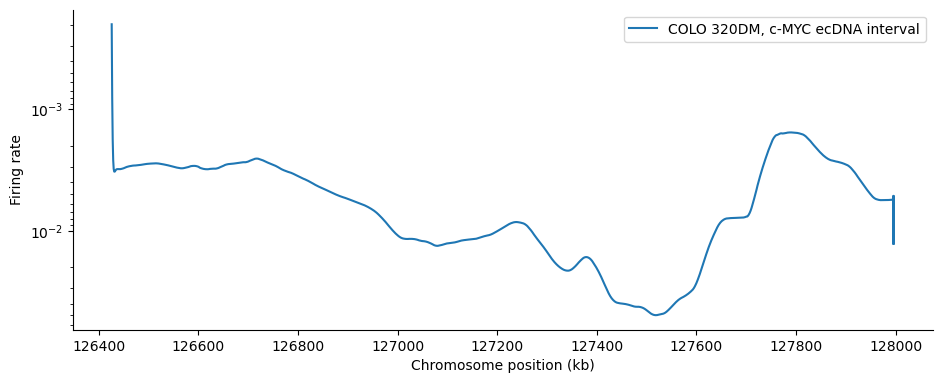

<Figure size 720x460 with 0 Axes>

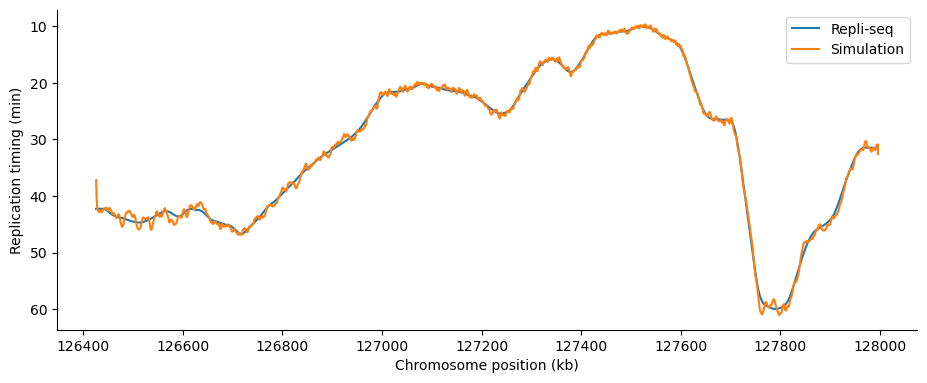

<Figure size 720x460 with 0 Axes>

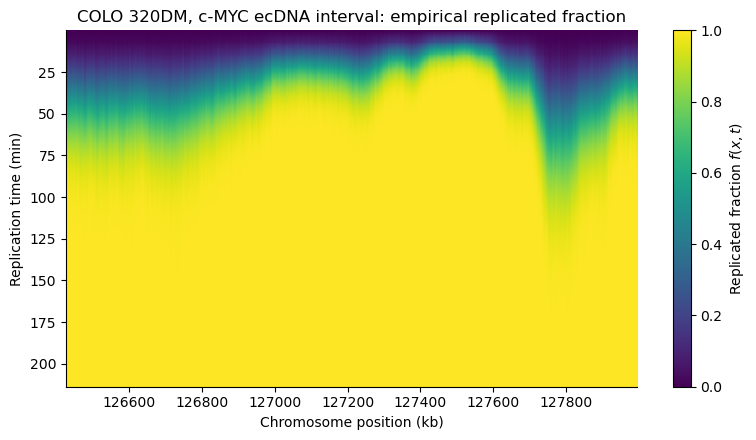

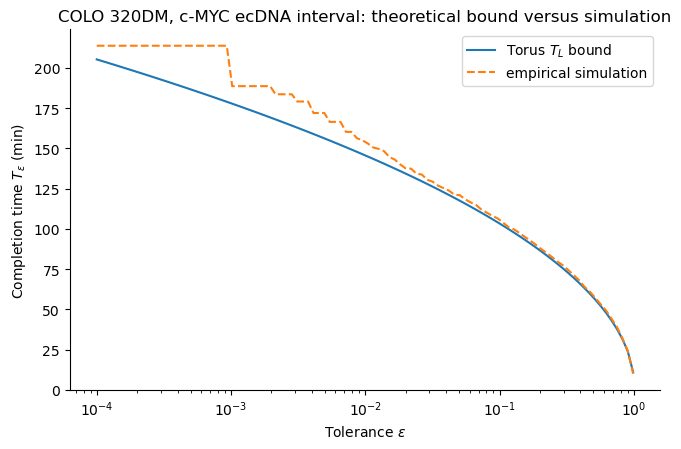

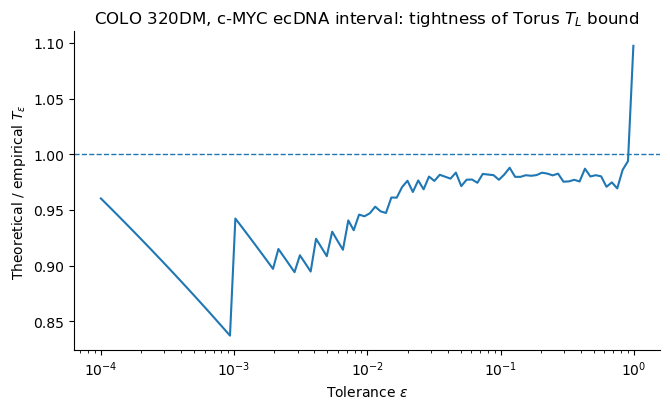

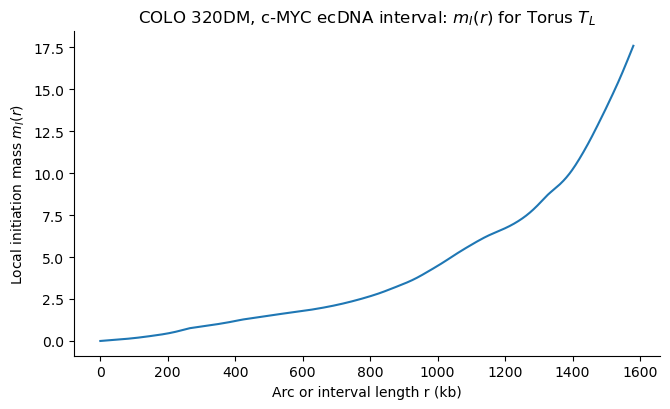

In [30]:
make_standard_plots(
    local_result,
    save_figures=True,
    show_domain_completion=False,
)

## A5. Optional local ecDNA batch loop

Run this only if you want to generate all selected local ecDNA datasets in a loop.

Processing: COLO 320DM, c-MYC ecDNA interval
Region: chr8:126425747-127997820
DNAscape periodicity: fit=True, simulation=True
Bound geometries: ['torus']
[1000/1000]  Elapsed: 00:00:18  ETA: 00:00:00E: 4.8466e-01

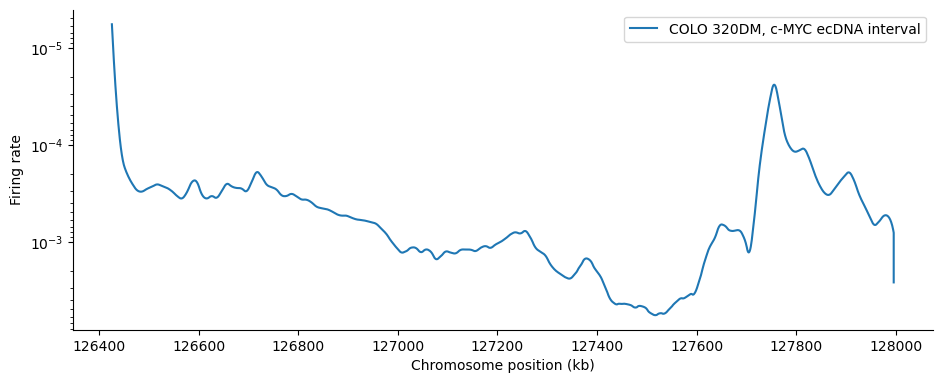

<Figure size 720x460 with 0 Axes>

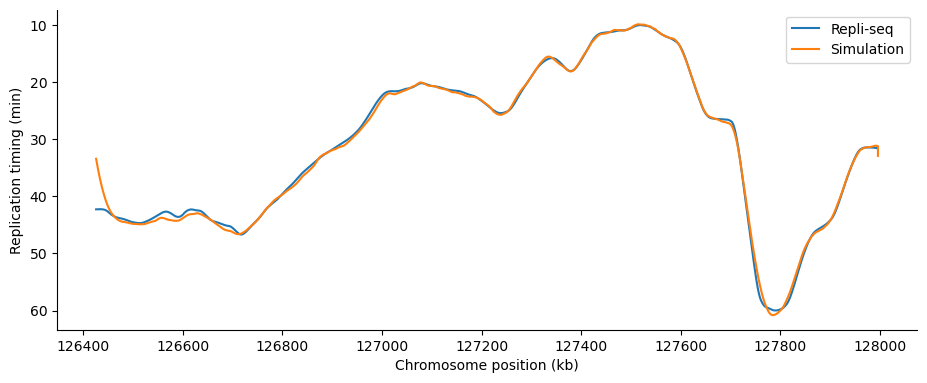

<Figure size 720x460 with 0 Axes>

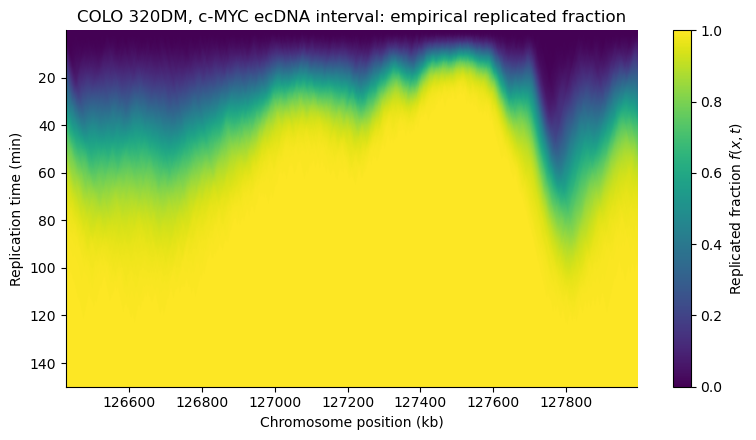

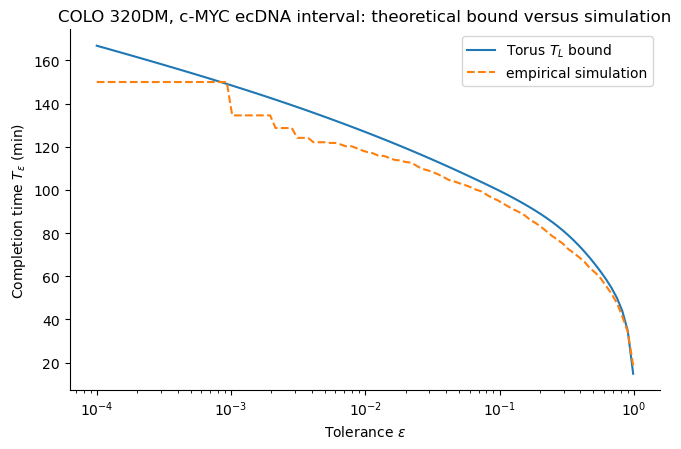

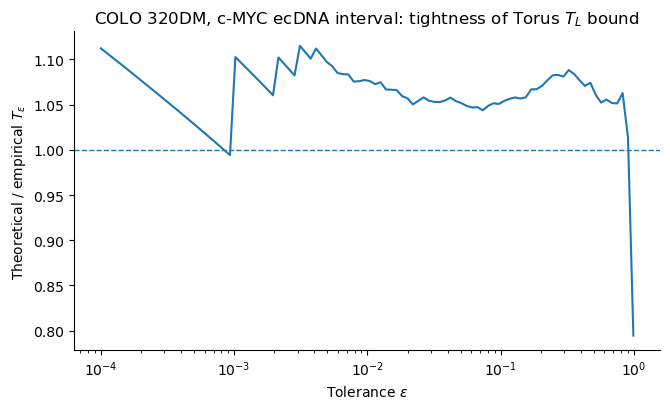

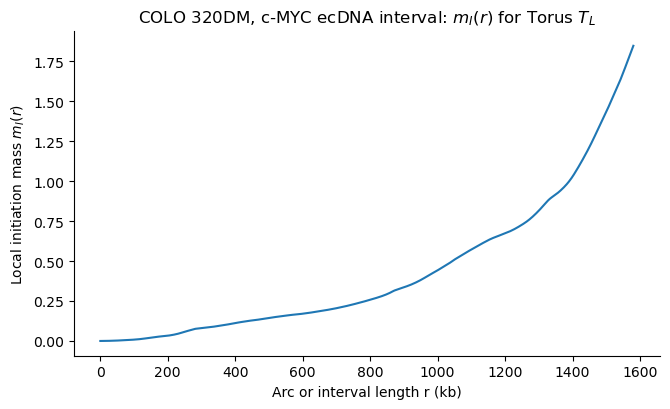

,dataset_key,dataset_label,geometry,epsilon,T_theory,T_empirical,theory_empirical_ratio
0,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",torus,0.100,166.79337,149.979752,1.112106
1,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",torus,0.050,166.79337,149.979752,1.112106
2,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",torus,0.010,166.79337,149.979752,1.112106
3,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",torus,0.001,166.79337,149.979752,1.112106


,dataset_key,dataset_label,geometry,epsilon,T_theory,T_empirical,theory_empirical_ratio
0,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",torus,0.100,166.79337,149.979752,1.112106
1,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",torus,0.050,166.79337,149.979752,1.112106
2,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",torus,0.010,166.79337,149.979752,1.112106
3,DM_ECDNA_EXACT,"COLO 320DM, c-MYC ecDNA interval",torus,0.001,166.79337,149.979752,1.112106


In [31]:
local_results = run_dataset_collection(
    LOCAL_ECDNA_DATASETS,
    selected_keys=LOCAL_RUN_KEYS,
    fork_speed=1.4,
    sim_number=1_000,
    refine_factor=10,
    smooth_window=50,
    timing_range=(60, 10),
    eps_grid=np.geomspace(1e-4, 0.99, 100),
    num_t_bound=4_000,
    empirical_mode="pointwise_uniform",
)

for result in local_results.values():
    make_standard_plots(result, save_figures=True)

completion_summary_table(local_results)

# Analysis B: whole-genome or whole-chromosome profiles

This section is for non-periodic chromosomal profiles. The DNAscape fit and simulation use `perQ=False`, and the theoretical comparison uses the full-line bound.

Because full-genome simulations can be large, this section is organised one chromosome at a time. Start with one chromosome, then expand the list when the workflow is stable.

## B1. Build whole-genome/chromosome dataset configurations

By default this prepares a single whole-chromosome profile for `chr20`. Replace `WHOLE_CHROMS` with `STANDARD_CHROMS` to prepare all autosomes and chrX.

In [21]:
WHOLE_CELL_LINE = "DM"

# Start small. Later, use:
# WHOLE_CHROMS = STANDARD_CHROMS
WHOLE_CHROMS = ["chr1"]

WHOLE_GENOME_DATASETS = build_chromosome_configs(
    cell_line=WHOLE_CELL_LINE,
    chroms=WHOLE_CHROMS,
    resolution=10_000,
    data_dir=DATA_DIR,
    analysis_tag="whole",
)

pd.DataFrame([
    {
        "key": key,
        "label": cfg["label"],
        "region": f"{cfg['chrom']}:{cfg['start']}-{cfg['end']}",
        "fit_periodic": cfg["fit_periodic"],
        "sim_periodic": cfg["sim_periodic"],
        "bounds": ", ".join(cfg["bound_geometries"]),
    }
    for key, cfg in WHOLE_GENOME_DATASETS.items()
])

,key,label,region,fit_periodic,sim_periodic,bounds
0,DM_whole_chr1,"DM, whole chr1",chr1:0-248950000,False,False,line


## B2. Check whole-genome/chromosome files

In [22]:
check_required_files(WHOLE_GENOME_DATASETS)

,dataset_key,dataset_label,file,exists
0,DM_whole_chr1,"DM, whole chr1",data\repliseq\DM_S1_10000.bw,True
1,DM_whole_chr1,"DM, whole chr1",data\repliseq\DM_S2_10000.bw,True
2,DM_whole_chr1,"DM, whole chr1",data\repliseq\DM_S3_10000.bw,True
3,DM_whole_chr1,"DM, whole chr1",data\repliseq\DM_S4_10000.bw,True
4,DM_whole_chr1,"DM, whole chr1",data\repliseq\DM_S5_10000.bw,True


,dataset_key,dataset_label,file,exists
0,DM_whole_chr1,"DM, whole chr1",data\repliseq\DM_S1_10000.bw,True
1,DM_whole_chr1,"DM, whole chr1",data\repliseq\DM_S2_10000.bw,True
2,DM_whole_chr1,"DM, whole chr1",data\repliseq\DM_S3_10000.bw,True
3,DM_whole_chr1,"DM, whole chr1",data\repliseq\DM_S4_10000.bw,True
4,DM_whole_chr1,"DM, whole chr1",data\repliseq\DM_S5_10000.bw,True


## B3. Run one non-periodic whole-chromosome analysis

For whole-chromosome simulations, the default `refine_factor=1` keeps the grid at 10 kb and avoids very large simulations. The simulation is non-periodic: `perQ=False`.

In [27]:
WHOLE_KEY = next(iter(WHOLE_GENOME_DATASETS))

whole_result = run_single_dataset(
    WHOLE_GENOME_DATASETS[WHOLE_KEY],
    fork_speed=1.4/10,
    sim_number=1_000,          # increase when runtime is acceptable
    refine_factor=1,           # keep whole-chromosome grid manageable
    smooth_window=25,
    timing_range=(600, 30),
    eps_grid=np.geomspace(1e-4, 0.99, 100),
    num_t_bound=4_000,
    empirical_mode="pointwise_uniform",
)

Processing: DM, whole chr1
Region: chr1:0-248950000
DNAscape periodicity: fit=False, simulation=False
Bound geometries: ['line']
[1000/1000]  Elapsed: 00:01:31  ETA: 00:00:00E: 2.1066e+02

## B4. Plot whole-genome/chromosome results

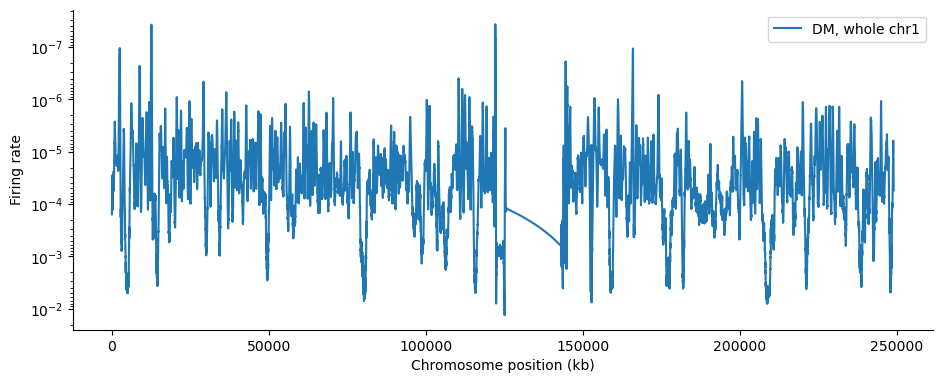

<Figure size 720x460 with 0 Axes>

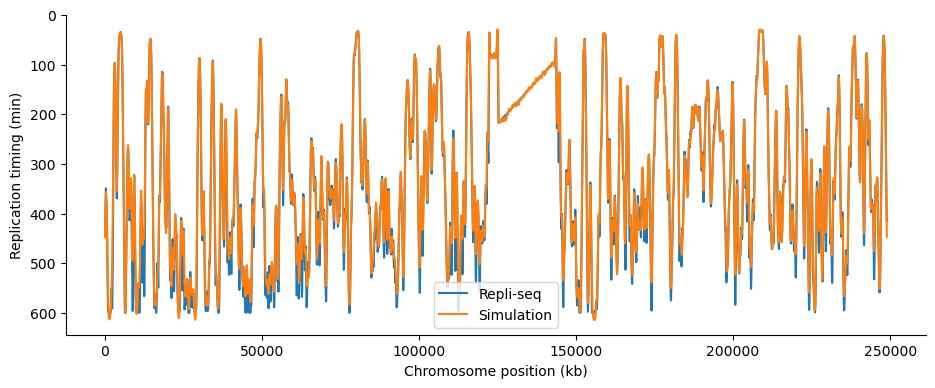

<Figure size 720x460 with 0 Axes>

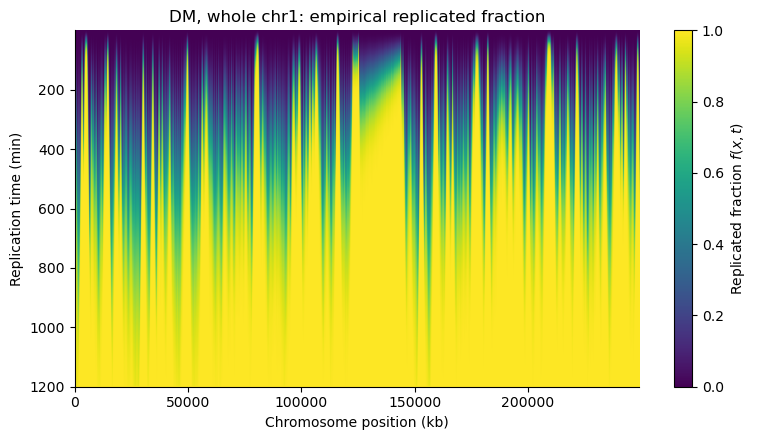

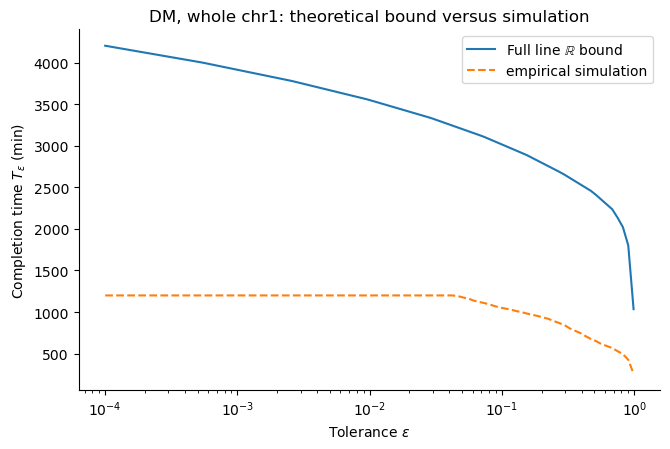

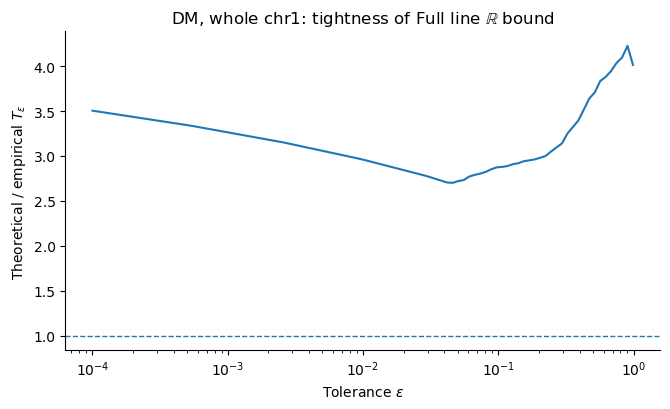

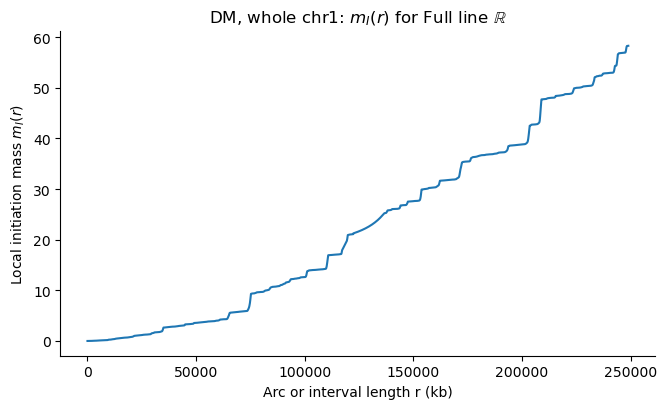

In [28]:
make_standard_plots(
    whole_result,
    save_figures=True,
    show_domain_completion=False,
)

## B5. Optional whole-genome batch loop

Use this when you are ready to run several chromosomes. The simulations are non-periodic throughout.

In [ ]:
# whole_results = run_dataset_collection(
#     WHOLE_GENOME_DATASETS,
#     selected_keys=list(WHOLE_GENOME_DATASETS),
#     fork_speed=1.4,
#     sim_number=1_000,
#     refine_factor=1,
#     smooth_window=25,
#     timing_range=(60, 10),
#     eps_grid=np.geomspace(1e-4, 0.99, 100),
#     num_t_bound=4_000,
#     empirical_mode="pointwise_uniform",
# )
#
# for result in whole_results.values():
#     make_standard_plots(result, save_figures=True)
#
# completion_summary_table(whole_results)

# Notes on interpretation

For the local COLO 320DM ecDNA interval, the torus bound is the natural theoretical object because the amplicon is circular. The DNAscape fit and stochastic simulations are therefore run with `perQ=True`.

For whole-genome or whole-chromosome profiles, the simulation is non-periodic and the comparison is made with the full-line bound. The local initiation mass is computed using non-wrapping intervals in the observed chromosome, not circular arcs. This keeps the analysis aligned with `perQ=False`.